In [2]:
#To check the structure of the MAT files
import numpy as np
from scipy.io import loadmat

# Path to a sample ground truth MAT file
gt_path = r"C:\Users\katel\OneDrive\Documents\OneDrive\Desktop\ShanghaiTechDataset\archive\ShanghaiTech\part_B\train_data\ground-truth\GT_IMG_1.mat"

# Load the MAT file
gt_data = loadmat(gt_path)

# Print the keys in the loaded MAT file
print("Keys in the loaded MAT file:", gt_data.keys())

# Print the structure and content of the MAT file
print("Contents of the loaded MAT file:")
for key, value in gt_data.items():
    if isinstance(value, bytes):
        print(key, type(value), len(value))  # Print length for bytes objects
    elif isinstance(value, np.ndarray):
        print(key, type(value), value.shape)  # Print shape for arrays
    else:
        print(key, type(value))  # Handle other types of objects


Keys in the loaded MAT file: dict_keys(['__header__', '__version__', '__globals__', 'image_info'])
Contents of the loaded MAT file:
__header__ <class 'bytes'> 76
__version__ <class 'str'>
__globals__ <class 'list'>
image_info <class 'numpy.ndarray'> (1, 1)


In [3]:
# Print the content of the image_info array
image_info = gt_data["image_info"]
print("Content of the image_info array:")
print(image_info)

Content of the image_info array:
[[array([[(array([[  32.67954877,  753.52165403],
                 [ 184.60695349,  690.79933098],
                 [ 344.89733461,  577.8991495 ],
                 [ 328.1713818 ,  536.08426746],
                 [ 329.5652112 ,  473.36194441],
                 [ 643.17682645,  533.29660866],
                 [ 661.29660866,  681.04252518],
                 [ 803.46720757,  580.6868083 ],
                 [ 814.61784278,  502.63236184],
                 [ 757.47083734,  392.51983915],
                 [ 770.01530195,  364.64325113],
                 [ 799.28571937,  315.85922209],
                 [ 728.20041991,  328.4036867 ],
                 [ 899.64143625,  405.06430376],
                 [ 919.15504786,  529.11512046],
                 [ 924.73036547,  278.22582826],
                 [ 965.1514181 ,  250.34924024],
                 [1018.11693534,  236.41094623],
                 [ 938.66865948,  186.23308779],
                 [ 896.85377745,  1

Number of training samples: 400
Number of testing samples: 316


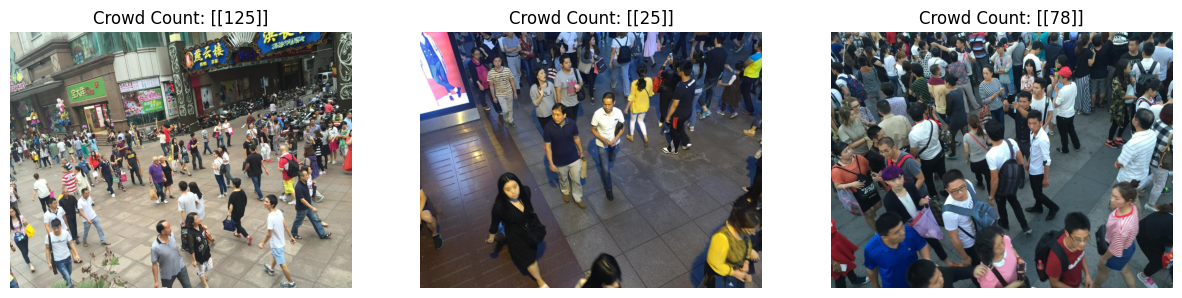

In [2]:
#Corrected Data Loading
#Data Loading
import os
import numpy as np
from scipy.io import loadmat
from PIL import Image
import matplotlib.pyplot as plt

def load_data(data_dir):
    image_dir = os.path.join(data_dir, "images")
    gt_dir = os.path.join(data_dir, "ground-truth")
    image_files = os.listdir(image_dir)
    
    data = []
    for image_file in image_files:
        image_path = os.path.join(image_dir, image_file)
        gt_path = os.path.join(gt_dir, "GT_" + os.path.splitext(image_file)[0] + ".mat")
        image = np.array(Image.open(image_path).convert("RGB"))  # Load image
        gt_data = loadmat(gt_path)  # Load ground truth MAT file
        crowd_count = gt_data["image_info"][0][0]['number'][0][0]  # Extract crowd count
        data.append({"image": image, "crowd_count": crowd_count})

    return data

# Paths to train and test data directories
train_data_dir = r"C:\Users\katel\OneDrive\Documents\OneDrive\Desktop\ShanghaiTechDataset\archive\ShanghaiTech\part_B\train_data"
test_data_dir = r"C:\Users\katel\OneDrive\Documents\OneDrive\Desktop\ShanghaiTechDataset\archive\ShanghaiTech\part_B\test_data"

# Load train and test data
train_data = load_data(train_data_dir)
test_data = load_data(test_data_dir)

# Display information about the loaded data
print("Number of training samples:", len(train_data))
print("Number of testing samples:", len(test_data))

# Display sample images with their crowd counts
num_samples_to_display = 3
sample_indices = np.random.choice(len(train_data), num_samples_to_display, replace=False)

plt.figure(figsize=(15, 6))
for i, idx in enumerate(sample_indices):
    plt.subplot(1, num_samples_to_display, i+1)
    plt.imshow(train_data[idx]["image"])
    plt.title(f"Crowd Count: {train_data[idx]['crowd_count']}")
    plt.axis("off")
plt.show()

Number of training samples: 400
Number of testing samples: 316


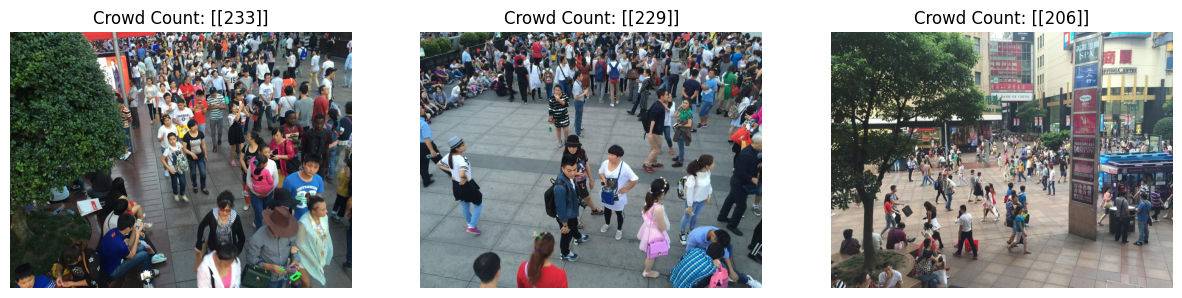

In [3]:
#Corrected Data Loading for first three images in the trained images 
import os
import numpy as np
from scipy.io import loadmat
from PIL import Image
import matplotlib.pyplot as plt

def load_data(data_dir):
    image_dir = os.path.join(data_dir, "images")
    gt_dir = os.path.join(data_dir, "ground-truth")
    image_files = os.listdir(image_dir)
    
    data = []
    for image_file in image_files:
        image_path = os.path.join(image_dir, image_file)
        gt_path = os.path.join(gt_dir, "GT_" + os.path.splitext(image_file)[0] + ".mat")
        image = np.array(Image.open(image_path).convert("RGB"))  # Load image
        gt_data = loadmat(gt_path)  # Load ground truth MAT file
        crowd_count = gt_data["image_info"][0][0]['number'][0][0]  # Extract crowd count
        data.append({"image": image, "crowd_count": crowd_count})

    return data

# Paths to train and test data directories
train_data_dir = r"C:\Users\katel\OneDrive\Documents\OneDrive\Desktop\ShanghaiTechDataset\archive\ShanghaiTech\part_B\train_data"
test_data_dir = r"C:\Users\katel\OneDrive\Documents\OneDrive\Desktop\ShanghaiTechDataset\archive\ShanghaiTech\part_B\test_data"

# Load train and test data
train_data = load_data(train_data_dir)
test_data = load_data(test_data_dir)

# Display information about the loaded data
print("Number of training samples:", len(train_data))
print("Number of testing samples:", len(test_data))

# Display crowd count for the first three images in the train data
num_samples_to_display = 3
sample_indices = np.arange(num_samples_to_display)

plt.figure(figsize=(15, 6))
for i, idx in enumerate(sample_indices):
    plt.subplot(1, num_samples_to_display, i+1)
    plt.imshow(train_data[idx]["image"])
    plt.title(f"Crowd Count: {train_data[idx]['crowd_count']}")
    plt.axis("off")
plt.show()

In [6]:
# To review the ground truth data and ensure that the crowd count values accurately represent the number of people in each image.
from scipy.io import loadmat

# Load the ground truth MAT file for a specific image
gt_path = r"C:\Users\katel\OneDrive\Documents\OneDrive\Desktop\ShanghaiTechDataset\archive\ShanghaiTech\part_B\train_data\ground-truth\GT_IMG_1.mat"
gt_data = loadmat(gt_path)

# Access the image_info array
image_info = gt_data["image_info"][0][0]

# Extract crowd count
crowd_count = image_info['number'][0][0]

# Optionally, visually inspect the image to verify the crowd count
# You can also compare the crowd count with your manual counting

print("Crowd Count from Ground Truth:", crowd_count)


Crowd Count from Ground Truth: [[233]]


In [7]:
#Data Preprocessing
import cv2
import numpy as np
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.utils import normalize

# Define function for preprocessing
def preprocess_data(data):
    images = []
    crowd_counts = []
    for sample in data:
        # Apply data cleaning if needed (e.g., remove noisy data points)
        if is_clean(sample):
            # Apply data augmentation
            augmented_samples = apply_augmentation(sample)
            for augmented_sample in augmented_samples:
                # Resize image to desired dimensions
                resized_image = resize_image(augmented_sample["image"], target_size=(224, 224))
                # Normalize image pixel values
                normalized_image = normalize(resized_image)
                images.append(normalized_image)
                # Normalize crowd count
                normalized_count = augmented_sample["crowd_count"] / 100000  # Scaling the count
                crowd_counts.append(normalized_count)
    
    return np.array(images), np.array(crowd_counts)

# Function to check if a sample is clean
def is_clean(sample):
    # Add logic to check if the sample is clean (e.g., based on quality, relevance, etc.)
    return True

# Function to apply data augmentation
def apply_augmentation(sample):
    # Initialize image data generator for augmentation
    datagen = ImageDataGenerator(
        rotation_range=10,
        width_shift_range=0.1,
        height_shift_range=0.1,
        zoom_range=0.1,
        horizontal_flip=True,
        vertical_flip=True,
        fill_mode='nearest'
    )
    
    augmented_samples = []
    image = np.expand_dims(sample["image"], axis=0)
    crowd_count = sample["crowd_count"]
    
    # Generate augmented images and crowd counts
    for img_aug, _ in datagen.flow(image, [crowd_count], batch_size=1):
        augmented_samples.append({"image": img_aug[0], "crowd_count": crowd_count})
        if len(augmented_samples) == 4:  # Adjust the number of augmented samples as needed
            break
    
    return augmented_samples

# Function to resize image
def resize_image(image, target_size):
    resized_image = cv2.resize(image, target_size)
    return resized_image

# Preprocess train and test data
train_images, train_counts = preprocess_data(train_data)
test_images, test_counts = preprocess_data(test_data)

# Split train data into train and validation sets
train_images, val_images, train_counts, val_counts = train_test_split(train_images, train_counts, test_size=0.1, random_state=42)

# Sample usage of preprocessed data
print("Train images shape:", train_images.shape)
print("Validation images shape:", val_images.shape)
print("Test images shape:", test_images.shape)
print("Example train crowd count:", train_counts[0])


Train images shape: (1440, 224, 224, 3)
Validation images shape: (160, 224, 224, 3)
Test images shape: (1264, 224, 224, 3)
Example train crowd count: [[0.00201]]


In [10]:
# Before augmentation
# Assign unique identifiers to each image and its corresponding ground truth count
train_data_indices = np.arange(len(train_images))
val_data_indices = np.arange(len(val_images))
test_data_indices = np.arange(len(test_images))

# After augmentation
# Verify alignment for training data
assert np.array_equal(train_data_indices, np.arange(len(train_images))), "Training data indices are not aligned after augmentation"
assert np.array_equal(val_data_indices, np.arange(len(val_images))), "Validation data indices are not aligned after augmentation"
assert np.array_equal(test_data_indices, np.arange(len(test_images))), "Test data indices are not aligned after augmentation"

print("Data indices remain aligned after augmentation.")

Data indices remain aligned after augmentation.


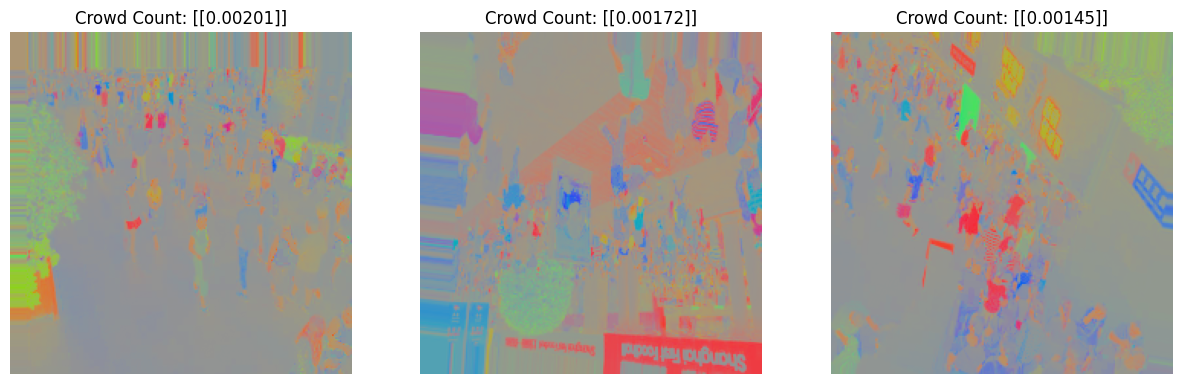

In [12]:
#Display Preprocessed Images
import matplotlib.pyplot as plt

# Define a function to display images with crowd counts
def display_images_with_counts(images, counts):
    num_images = len(images)
    plt.figure(figsize=(15, 6))
    for i in range(num_images):
        plt.subplot(1, num_images, i+1)
        plt.imshow(images[i])
        plt.title(f"Crowd Count: {counts[i]}")
        plt.axis("off")
    plt.show()

# Display the first three preprocessed images with their crowd counts
display_images_with_counts(train_images[:3], train_counts[:3])



In [15]:
#CSRNet Model Architecture
from tensorflow.keras.models import load_model

# Load the saved model
model = load_model(r"C:\Users\katel\OneDrive\Documents\OneDrive\Desktop\ShanghaiTechDataset\archive\ShanghaiTech\part_B\CSRNet Model")

# Display model architecture
print("Model Architecture:")
model.summary()

Model Architecture:
Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_11 (Conv2D)          (None, 224, 224, 64)      1792      
                                                                 
 conv2d_12 (Conv2D)          (None, 224, 224, 64)      36928     
                                                                 
 max_pooling2d_3 (MaxPoolin  (None, 112, 112, 64)      0         
 g2D)                                                            
                                                                 
 conv2d_13 (Conv2D)          (None, 112, 112, 128)     73856     
                                                                 
 conv2d_14 (Conv2D)          (None, 112, 112, 128)     147584    
                                                                 
 max_pooling2d_4 (MaxPoolin  (None, 56, 56, 128)       0         
 g2D)                             

In [23]:
#Model Evaluation using MSE
# Evaluate the trained model on the validation dataset
val_loss = model.evaluate(val_images, val_counts)
print("Validation loss:", val_loss)


5/5 [==============================] - 18s 4s/step - loss: 0.4885
Validation loss: 0.48846474289894104


In [55]:
#Safety Classification
# Define safety threshold
safety_threshold = 0.3  # Adjust the threshold based on your requirements

# Perform safety classification on test dataset
predictions = model.predict(test_images)  # Assuming `model` is your trained CSRNet model

# Print safety threshold and predictions
print("Safety Threshold:", safety_threshold)
print("Predictions:", predictions)

for i in range(len(predictions)):
    predicted_counts = predictions[i]
    if (predicted_counts < safety_threshold).any():
        print(f"Crowd {i+1} is SAFE")
    else:
        print(f"Crowd {i+1} is UNSAFE")




40/40 [==============================] - 185s 5s/step
Safety Threshold: 0.3
Predictions: [[[[0.5991657 ]
   [0.66525054]
   [0.6740056 ]
   ...
   [0.6747527 ]
   [0.66603345]
   [0.59908324]]

  [[0.64182436]
   [0.6848898 ]
   [0.6956097 ]
   ...
   [0.6959413 ]
   [0.688294  ]
   [0.6430917 ]]

  [[0.64763165]
   [0.69489276]
   [0.7055534 ]
   ...
   [0.7054966 ]
   [0.6966853 ]
   [0.6475238 ]]

  ...

  [[0.65281045]
   [0.6961236 ]
   [0.70879006]
   ...
   [0.70896614]
   [0.69821525]
   [0.65264237]]

  [[0.6451273 ]
   [0.6858376 ]
   [0.69668436]
   ...
   [0.696632  ]
   [0.6867448 ]
   [0.64620906]]

  [[0.60207915]
   [0.66653347]
   [0.67488885]
   ...
   [0.67493147]
   [0.6688117 ]
   [0.6080227 ]]]


 [[[0.59784377]
   [0.66275907]
   [0.6715566 ]
   ...
   [0.676573  ]
   [0.66779196]
   [0.6001128 ]]

  [[0.6422838 ]
   [0.6849855 ]
   [0.69559455]
   ...
   [0.6958544 ]
   [0.6882194 ]
   [0.64289224]]

  [[0.6480865 ]
   [0.69505394]
   [0.7058317 ]
   ...
   [0.7

In [1]:
print(predictions.shape)

NameError: name 'predictions' is not defined